In [7]:
"""
Bankruptcy Prediction – Modeling & Validation Pipeline
======================================================
- 80/20 stratified holdout
- 5-fold stratified CV on the training portion only
- Full preprocessing (imputation, missingness indicators, scaling,
  feature selection) fitted INSIDE each fold → no leakage
- Models: Logistic Regression, KNN, Decision Tree, Random Forest,
  Gradient Boosting, SVM
- Metrics: PR-AUC (Average Precision), ROC-AUC, Recall, Precision, F1
  (Accuracy reported only as context)
- Class weighting compared where available
- Overfitting check (train vs CV) + final evaluation on untouched holdout
"""

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, accuracy_score,
    precision_recall_curve, roc_curve, classification_report,
    confusion_matrix
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
plt.style.use('seaborn-v0_8-whitegrid')

# ============================================================
# 0. PATHS
# ============================================================
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) #if 'notebooks' in os.getcwd() else os.getcwd()
DATA_PATH    = os.path.join(PROJECT_ROOT, 'data', 'processed','bankruptcy_2yr.csv')
FIG_DIR      = os.path.join(PROJECT_ROOT, 'results', 'figures')
TAB_DIR      = os.path.join(PROJECT_ROOT, 'results', 'tables')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

RANDOM_STATE = 42
N_JOBS = -1

# ============================================================
# 1. LOAD DATA
# ============================================================
df = pd.read_csv(DATA_PATH)
print(f"Loaded shape: {df.shape}")
print(f"Class balance:\n{df['class'].value_counts(normalize=True).round(3)}")

X = df.drop(columns=['class'])
y = df['class']

feature_names = X.columns.tolist()


Loaded shape: (9792, 65)
Class balance:
class
0    0.947
1    0.053
Name: proportion, dtype: float64


In [8]:

# ============================================================
# 2. CUSTOM TRANSFORMER – Missingness Indicators
# ============================================================
class MissingnessIndicator(BaseEstimator, TransformerMixin):
    """Creates binary indicator columns for every feature that has missing values.
    Indicators are created on the training data and applied consistently."""
    def __init__(self):
        self.missing_cols_ = None

    def fit(self, X, y=None):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        self.missing_cols_ = X.columns[X.isnull().any()].tolist()
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for col in self.missing_cols_:
            X[f'{col}_missing'] = X[col].isnull().astype(int)
        return X

    def get_feature_names_out(self, input_features=None):
        # Will be handled by the pipeline later
        return None


In [9]:

# ============================================================
# 3. PREPROCESSING PIPELINE (fitted inside CV folds)
# ============================================================
def build_preprocessor(k_best=30):
    """
    Full preprocessing chain:
    1. Missingness indicators
    2. Median imputation
    3. Standard scaling
    4. SelectKBest (ANOVA F-value)
    All steps are fitted only on the data they see → no leakage.
    """
    return Pipeline([
        ('missing_ind', MissingnessIndicator()),
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=f_classif, k=k_best))
    ])


<h3>MODEL SUITABILITY NOTES</h3>

<!--
<h4 style="margin-bottom: 4px; border-bottom: 1px solid #ccc; padding-bottom: 5px;">Model Suitability & Limitations for this bankruptcy task</h4>
-->
<p style="margin-bottom: 2px; font-weight: bold;">1. Logistic Regression (baseline)</p>
<ul style="margin-top: 0; margin-bottom: 14px; padding-left: 20px;">
   <li>Interpretable coefficients, fast, works well with linear decision boundaries</li>
   <li>Supports class_weight='balanced'</li>
   <li>Assumes linear relationship in the logit; may underfit complex interactions</li>
   <li>Sensitive to multicollinearity (common among financial ratios)</li>
</ul>
 
<p style="margin-bottom: 2px; font-weight: bold;">2. K-Nearest Neighbors</p>
<ul style="margin-top: 0; margin-bottom: 14px; padding-left: 20px;">
   <li>Non-parametric, can capture local structure</li>
   <li>Suffers from the curse of dimensionality (we have 64+ features)</li>
   <li>Sensitive to scaling and distance metric</li>
   <li>No native class_weight; minority class can be dominated by majority neighbours</li>
   <li>Slow at prediction time</li>
</ul>

<p style="margin-bottom: 2px; font-weight: bold;">3. Decision Tree</p>
<ul style="margin-top: 0; margin-bottom: 14px; padding-left: 20px;">
   <li>Captures non-linear interactions and is highly interpretable</li>
   <li>Handles mixed scales without explicit scaling (still scaled here for consistency)</li>
   <li>High variance / easy to overfit, especially with deep trees</li>
   <li>Supports class_weight</li>
</ul>

<p style="margin-bottom: 2px; font-weight: bold;">4. Random Forest</p>
<ul style="margin-top: 0; margin-bottom: 14px; padding-left: 20px;">
   <li>Reduces variance of single trees via bagging + feature randomness</li>
   <li>Robust to outliers and non-linearities; good default for tabular data</li>
   <li>Supports class_weight / sample weights</li>
   <li>Less interpretable than a single tree</li>
   <li>Can still overfit if not regularised (max_depth, min_samples_leaf)</li>
</ul>

<p style="margin-bottom: 2px; font-weight: bold;">5. Gradient Boosting</p>
<ul style="margin-top: 0; margin-bottom: 14px; padding-left: 20px;">
   <li>Often the strongest pure-sklearn ensemble for tabular data</li>
   <li>Sequential residual fitting captures complex patterns</li>
   <li>Sensitive to hyperparameters (learning_rate, n_estimators, max_depth)</li>
   <li>No native class_weight in older sklearn versions (we use sample_weight)</li>
   <li>Longer training time</li>
</ul>

<p style="margin-bottom: 2px; font-weight: bold;">6. Support Vector Machine (RBF)</p>
<ul style="margin-top: 0; margin-bottom: 0px; padding-left: 20px;">
   <li>Effective in high-dimensional spaces; kernel trick captures non-linearity</li>
   <li>Supports class_weight='balanced'</li>
   <li>Scales poorly with sample size</li>
   <li>Requires careful scaling and hyperparameter search (C, gamma)</li>
   <li>Probability estimates via Platt scaling (probability=True) are approximate</li>
</ul>


In [10]:

# ============================================================
# 4. MODEL DEFINITIONS
# ============================================================

# Hyperparameter grids (kept modest for reasonable runtime)
param_grids = {
    'LogisticRegression': {
        'clf__C': [0.01, 0.1, 1.0, 10.0],
        'clf__class_weight': [None, 'balanced'],
        'clf__penalty': ['l2'],
        'clf__solver': ['lbfgs'],
        'clf__max_iter': [1000]
    },
    'KNN': {
        'clf__n_neighbors': [3, 5, 7, 11],
        'clf__weights': ['uniform', 'distance'],
        'clf__p': [1, 2]
    },
    'DecisionTree': {
        'clf__max_depth': [3, 5, 8, 12, None],
        'clf__min_samples_leaf': [5, 10, 20],
        'clf__class_weight': [None, 'balanced']
    },
    'RandomForest': {
        'clf__n_estimators': [100, 200],
        'clf__max_depth': [6, 10, None],
        'clf__min_samples_leaf': [5, 10],
        'clf__class_weight': [None, 'balanced', 'balanced_subsample']
    },
    'GradientBoosting': {
        'clf__n_estimators': [100, 200],
        'clf__learning_rate': [0.05, 0.1],
        'clf__max_depth': [3, 5],
        'clf__min_samples_leaf': [10, 20]
    },
    'SVM': {
        'clf__C': [0.1, 1.0, 10.0],
        'clf__gamma': ['scale', 0.01],
        'clf__class_weight': [None, 'balanced'],
        'clf__probability': [True]          # needed for AUC metrics
    }
}

base_estimators = {
    'LogisticRegression': LogisticRegression(random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(),
    'DecisionTree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS),
    'GradientBoosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(random_state=RANDOM_STATE)
}


In [11]:
# ============================================================
# 5. TRAIN / HOLDOUT SPLIT (80/20 stratified)
# ============================================================
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"\nTrain size : {X_train.shape[0]}  (pos={y_train.sum()})")
print(f"Holdout size: {X_holdout.shape[0]}  (pos={y_holdout.sum()})")



Train size : 7833  (pos=412)
Holdout size: 1959  (pos=103)


In [12]:
# ============================================================
# 6. CROSS-VALIDATION + HYPERPARAMETER SEARCH
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'pr_auc'   : 'average_precision',
    'roc_auc'  : 'roc_auc',
    'recall'   : 'recall',
    'precision': 'precision',
    'f1'       : 'f1',
    'accuracy' : 'accuracy'
}

cv_results = {}
best_pipelines = {}

for name, estimator in base_estimators.items():
    print(f"\n{'='*60}")
    print(f"Tuning {name} …")
    print('='*60)

    pipe = Pipeline([
        ('preproc', build_preprocessor(k_best=30)),
        ('clf', estimator)
    ])

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        scoring='average_precision',      # primary metric = PR-AUC
        cv=cv,
        n_jobs=N_JOBS,
        refit=True,
        return_train_score=True,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_pipelines[name] = grid.best_estimator_
    cv_results[name] = {
        'best_params'   : grid.best_params_,
        'best_pr_auc'   : grid.best_score_,
        'cv_results_df' : pd.DataFrame(grid.cv_results_)
    }

    # Detailed CV metrics for the best estimator
    detailed = cross_validate(
        grid.best_estimator_,
        X_train, y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=N_JOBS
    )

    summary = {}
    for metric in scoring:
        summary[f'cv_{metric}_mean']  = detailed[f'test_{metric}'].mean()
        summary[f'cv_{metric}_std']   = detailed[f'test_{metric}'].std()
        summary[f'train_{metric}_mean'] = detailed[f'train_{metric}'].mean()

    cv_results[name]['metrics'] = summary
    print(f"Best PR-AUC (CV): {grid.best_score_:.4f}")
    print(f"Best params: {grid.best_params_}")



Tuning LogisticRegression …
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best PR-AUC (CV): 0.3962
Best params: {'clf__C': 10.0, 'clf__class_weight': None, 'clf__max_iter': 1000, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}

Tuning KNN …
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best PR-AUC (CV): 0.4368
Best params: {'clf__n_neighbors': 11, 'clf__p': 2, 'clf__weights': 'uniform'}

Tuning DecisionTree …
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best PR-AUC (CV): 0.4918
Best params: {'clf__class_weight': None, 'clf__max_depth': 8, 'clf__min_samples_leaf': 10}

Tuning RandomForest …
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best PR-AUC (CV): 0.5489
Best params: {'clf__class_weight': None, 'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}

Tuning GradientBoosting …
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best PR-AUC (CV): 0.5626
Best params: {'clf__learning_rate': 0.0

In [13]:
# ============================================================
# 7. COLLECT & SAVE CV RESULTS
# ============================================================
rows = []
for name, res in cv_results.items():
    m = res['metrics']
    rows.append({
        'model'            : name,
        'best_params'      : str(res['best_params']),
        'cv_pr_auc'        : m['cv_pr_auc_mean'],
        'cv_pr_auc_std'    : m['cv_pr_auc_std'],
        'train_pr_auc'     : m['train_pr_auc_mean'],
        'cv_roc_auc'       : m['cv_roc_auc_mean'],
        'cv_recall'        : m['cv_recall_mean'],
        'cv_precision'     : m['cv_precision_mean'],
        'cv_f1'            : m['cv_f1_mean'],
        'cv_accuracy'      : m['cv_accuracy_mean'],
        'overfit_gap_pr'   : m['train_pr_auc_mean'] - m['cv_pr_auc_mean']
    })

cv_summary = pd.DataFrame(rows).sort_values('cv_pr_auc', ascending=False)
cv_summary.to_csv(os.path.join(TAB_DIR, '12_cv_model_comparison.csv'), index=False)
print("\nSaved → tables/12_cv_model_comparison.csv")
print(cv_summary[['model', 'cv_pr_auc', 'cv_roc_auc', 'cv_recall', 'cv_f1', 'overfit_gap_pr']].round(4))



Saved → tables/12_cv_model_comparison.csv
                model  cv_pr_auc  cv_roc_auc  cv_recall   cv_f1  \
4    GradientBoosting     0.5626      0.8844     0.4250  0.5555   
3        RandomForest     0.5489      0.8842     0.2817  0.4218   
2        DecisionTree     0.4918      0.8279     0.3813  0.5038   
5                 SVM     0.4619      0.7673     0.3327  0.4631   
1                 KNN     0.4368      0.7993     0.3399  0.4711   
0  LogisticRegression     0.3962      0.8164     0.1920  0.2978   

   overfit_gap_pr  
4          0.2246  
3          0.3563  
2          0.1628  
5          0.1006  
1          0.1118  
0          0.0106  


In [14]:
# ============================================================
# 8. SELECT BEST MODEL (highest CV PR-AUC)
# ============================================================
best_model_name = cv_summary.iloc[0]['model']
best_pipe = best_pipelines[best_model_name]
print(f"\n>>> Selected model: {best_model_name}")



>>> Selected model: GradientBoosting


In [15]:

# ============================================================
# 9. FINAL EVALUATION ON UNTOUCHED HOLDOUT
# ============================================================
y_hold_proba = best_pipe.predict_proba(X_holdout)[:, 1]
y_hold_pred  = best_pipe.predict(X_holdout)

holdout_metrics = {
    'PR-AUC'     : average_precision_score(y_holdout, y_hold_proba),
    'ROC-AUC'    : roc_auc_score(y_holdout, y_hold_proba),
    'Recall'     : recall_score(y_holdout, y_hold_pred),
    'Precision'  : precision_score(y_holdout, y_hold_pred),
    'F1'         : f1_score(y_holdout, y_hold_pred),
    'Accuracy'   : accuracy_score(y_holdout, y_hold_pred)
}

print("\nHoldout performance of selected model:")
for k, v in holdout_metrics.items():
    print(f"  {k:12s}: {v:.4f}")

holdout_df = pd.DataFrame([holdout_metrics], index=[best_model_name])
holdout_df.to_csv(os.path.join(TAB_DIR, '13_holdout_performance.csv'))
print("Saved → tables/13_holdout_performance.csv")

# Classification report
report = classification_report(y_holdout, y_hold_pred, output_dict=True)
pd.DataFrame(report).T.to_csv(os.path.join(TAB_DIR, '14_holdout_classification_report.csv'))
print("Saved → tables/14_holdout_classification_report.csv")




Holdout performance of selected model:
  PR-AUC      : 0.6109
  ROC-AUC     : 0.8841
  Recall      : 0.4369
  Precision   : 0.8333
  F1          : 0.5732
  Accuracy    : 0.9658
Saved → tables/13_holdout_performance.csv
Saved → tables/14_holdout_classification_report.csv


In [16]:
# ============================================================
# 10. VISUALISATIONS
# ============================================================

# --- 10a. CV metric comparison bar plot ---
metrics_to_plot = ['cv_pr_auc', 'cv_roc_auc', 'cv_recall', 'cv_precision', 'cv_f1']
plot_df = cv_summary.set_index('model')[metrics_to_plot]

fig, ax = plt.subplots(figsize=(12, 6))
plot_df.plot(kind='bar', ax=ax, width=0.8)
ax.set_title('Cross-Validation Metrics by Model (5-fold Stratified)', fontsize=14)
ax.set_ylabel('Score')
ax.legend(loc='lower right')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '09_cv_metrics_comparison.png'), dpi=150, bbox_inches='tight')
plt.close()
print("Saved → figures/09_cv_metrics_comparison.png")

# --- 10b. Overfitting gap ---
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x='model', y='overfit_gap_pr', data=cv_summary, palette='coolwarm', ax=ax)
ax.axhline(0, color='black', lw=1)
ax.set_title('Overfitting Gap (Train PR-AUC − CV PR-AUC)')
ax.set_ylabel('Gap')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '10_overfitting_gap.png'), dpi=150, bbox_inches='tight')
plt.close()
print("Saved → figures/10_overfitting_gap.png")

# --- 10c. PR & ROC curves on holdout ---
precision, recall, _ = precision_recall_curve(y_holdout, y_hold_proba)
fpr, tpr, _ = roc_curve(y_holdout, y_hold_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(recall, precision, lw=2, label=f'PR-AUC = {holdout_metrics["PR-AUC"]:.3f}')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title(f'Precision-Recall Curve – {best_model_name}')
axes[0].legend(loc='lower left')
axes[0].grid(True, alpha=0.3)

axes[1].plot(fpr, tpr, lw=2, label=f'ROC-AUC = {holdout_metrics["ROC-AUC"]:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title(f'ROC Curve – {best_model_name}')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '11_holdout_pr_roc_curves.png'), dpi=150, bbox_inches='tight')
plt.close()
print("Saved → figures/11_holdout_pr_roc_curves.png")

# --- 10d. Confusion matrix ---
cm = confusion_matrix(y_holdout, y_hold_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Non-bankrupt', 'Bankrupt'],
            yticklabels=['Non-bankrupt', 'Bankrupt'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Holdout Confusion Matrix – {best_model_name}')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '12_holdout_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.close()
print("Saved → figures/12_holdout_confusion_matrix.png")

print("\n" + "="*60)
print("PIPELINE COMPLETE")
print("="*60)
print(f"Best model selected by CV PR-AUC: {best_model_name}")
print(f"Holdout PR-AUC: {holdout_metrics['PR-AUC']:.4f}")

Saved → figures/09_cv_metrics_comparison.png
Saved → figures/10_overfitting_gap.png
Saved → figures/11_holdout_pr_roc_curves.png
Saved → figures/12_holdout_confusion_matrix.png

PIPELINE COMPLETE
Best model selected by CV PR-AUC: GradientBoosting
Holdout PR-AUC: 0.6109


### Follow-up experiments: leading ensemble models

The initial six-model comparison above is retained unchanged. This section evaluates **Random Forest** and **Gradient Boosting** on the **training data only**, testing the EDA-motivated preprocessing choices: missingness indicators, feature selection, and (for comparison) scaling. All transformations are fitted inside cross-validation folds. The experiment uses the previously selected classifier hyperparameters; results are exploratory because those hyperparameters were selected using the same training dataset. The holdout set is **not** used to choose a configuration or threshold.

In [17]:
# ============================================================
# 11. Sensitivity testing on the leading ensemble models
# ============================================================

# Training-only preprocessing sensitivity experiments

from sklearn.base import clone
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_fscore_support

TOP_MODELS = ['GradientBoosting', 'RandomForest']
experiment_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Small, interpretable set of configurations rather than a large exhaustive search.
configurations = {
    'original':       dict(indicators=True,  scaler='standard', select=30),
    'no_indicators':  dict(indicators=False, scaler='standard', select=30),
    'all_features':   dict(indicators=True,  scaler='standard', select='all'),
    'robust_scaling': dict(indicators=True,  scaler='robust',   select=30),
    'no_scaling':     dict(indicators=True,  scaler='none',     select=30),
}

def make_experiment_pipeline(name, config):
    # Reuse tuned classifier settings, but rebuild all preprocessing from scratch.
    tuned_clf = clone(best_pipelines[name].named_steps['clf'])
    steps = []
    if config['indicators']:
        steps.append(('missing_ind', MissingnessIndicator()))
    steps.append(('imputer', SimpleImputer(strategy='median')))
    if config['scaler'] == 'standard':
        steps.append(('scaler', StandardScaler()))
    elif config['scaler'] == 'robust':
        steps.append(('scaler', RobustScaler()))
    if config['select'] != 'all':
        steps.append(('selector', SelectKBest(score_func=f_classif, k=config['select'])))
    return Pipeline([('preproc', Pipeline(steps)), ('clf', tuned_clf)])

experiment_rows = []
for model_name in TOP_MODELS:
    for config_name, config in configurations.items():
        pipe = make_experiment_pipeline(model_name, config)
        scores = cross_validate(
            pipe, X_train, y_train, cv=experiment_cv,
            scoring={'pr_auc': 'average_precision', 'roc_auc': 'roc_auc',
                     'recall': 'recall', 'precision': 'precision', 'f1': 'f1'},
            n_jobs=N_JOBS, return_train_score=True
        )
        experiment_rows.append({
            'model': model_name, 'configuration': config_name,
            'cv_pr_auc': scores['test_pr_auc'].mean(),
            'cv_pr_auc_std': scores['test_pr_auc'].std(),
            'train_pr_auc': scores['train_pr_auc'].mean(),
            'cv_roc_auc': scores['test_roc_auc'].mean(),
            'cv_recall': scores['test_recall'].mean(),
            'cv_precision': scores['test_precision'].mean(),
            'cv_f1': scores['test_f1'].mean()
        })

experiment_summary = pd.DataFrame(experiment_rows).sort_values('cv_pr_auc', ascending=False)
experiment_summary.to_csv(os.path.join(TAB_DIR, '17_ensemble_preprocessing_experiments.csv'), index=False)
print(experiment_summary.round(4).to_string(index=False))
print('Saved: results/tables/17_ensemble_preprocessing_experiments.csv')

           model  configuration  cv_pr_auc  cv_pr_auc_std  train_pr_auc  cv_roc_auc  cv_recall  cv_precision  cv_f1
GradientBoosting   all_features     0.6970         0.0515        0.9165      0.9320     0.4517        0.9024 0.5975
    RandomForest   all_features     0.6218         0.0415        0.9803      0.9162     0.1530        1.0000 0.2631
GradientBoosting     no_scaling     0.5626         0.0672        0.7872      0.8844     0.4250        0.8121 0.5555
GradientBoosting       original     0.5626         0.0672        0.7872      0.8844     0.4250        0.8121 0.5555
GradientBoosting robust_scaling     0.5626         0.0672        0.7872      0.8844     0.4250        0.8121 0.5555
    RandomForest robust_scaling     0.5490         0.0536        0.9052      0.8842     0.2817        0.8449 0.4218
    RandomForest     no_scaling     0.5490         0.0536        0.9052      0.8842     0.2817        0.8449 0.4218
    RandomForest       original     0.5489         0.0536        0.9052 

## 12. Precision–recall tradeoff

Select the best follow-up **model and preprocessing configuration by mean training CV average precision**. Generate out-of-fold probabilities on the training partition and evaluate alternative thresholds.

Selected model: GradientBoosting
Selected preprocessing: all_features
Training OOF average precision: 0.6954
Illustrative max-F1 threshold (training only): 0.25
 threshold  precision  recall     f1  flagged_companies  bankruptcies_detected  bankruptcies_missed
      0.10     0.4754  0.7039 0.5675                610                    290                  122
      0.15     0.6202  0.6262 0.6232                416                    258                  154
      0.20     0.6953  0.5704 0.6267                338                    235                  177
      0.25     0.7612  0.5340 0.6277                289                    220                  192
      0.30     0.8000  0.5146 0.6263                265                    212                  200
      0.35     0.8367  0.4976 0.6240                245                    205                  207
      0.40     0.8646  0.4806 0.6178                229                    198                  214
      0.45     0.8727  0.4660 0.6076   

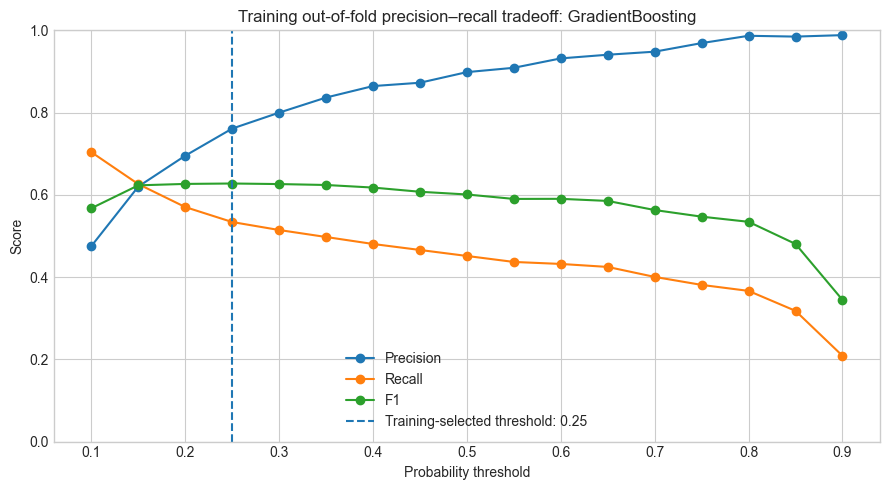

Saved: results/figures/17_training_threshold_tradeoff.png


In [18]:
# ============================================================================
# 12. Out-of-fold probabilities and precision/recall at different thresholds
# ===========================================================================

winner = experiment_summary.iloc[0]
selected_model_name = winner['model']
selected_config_name = winner['configuration']
selected_pipe = make_experiment_pipeline(
    selected_model_name, configurations[selected_config_name]
)

oof_proba = cross_val_predict(
    selected_pipe, X_train, y_train,
    cv=experiment_cv, method='predict_proba', n_jobs=N_JOBS
)[:, 1]

# Illustrative operating thresholds; all evaluation below uses training OOF predictions.
thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)
threshold_rows = []
for threshold in thresholds:
    predicted = (oof_proba >= threshold).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_train, predicted, average='binary', zero_division=0
    )
    threshold_rows.append({
        'threshold': threshold, 'precision': precision, 'recall': recall,
        'f1': f1, 'flagged_companies': int(predicted.sum()),
        'bankruptcies_detected': int(((predicted == 1) & (y_train == 1)).sum()),
        'bankruptcies_missed': int(((predicted == 0) & (y_train == 1)).sum())
    })
threshold_table = pd.DataFrame(threshold_rows)
selected_threshold = float(threshold_table.loc[threshold_table['f1'].idxmax(), 'threshold'])
threshold_table.to_csv(os.path.join(TAB_DIR, '18_training_threshold_tradeoff.csv'), index=False)
print(f'Selected model: {selected_model_name}')
print(f'Selected preprocessing: {selected_config_name}')
print(f'Training OOF average precision: {average_precision_score(y_train, oof_proba):.4f}')
print(f'Illustrative max-F1 threshold (training only): {selected_threshold:.2f}')
print(threshold_table.round(4).to_string(index=False))
print('Saved: results/tables/18_training_threshold_tradeoff.csv')

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(threshold_table['threshold'], threshold_table['precision'], marker='o', label='Precision')
ax.plot(threshold_table['threshold'], threshold_table['recall'], marker='o', label='Recall')
ax.plot(threshold_table['threshold'], threshold_table['f1'], marker='o', label='F1')
ax.axvline(selected_threshold, linestyle='--', label=f'Training-selected threshold: {selected_threshold:.2f}')
ax.set(xlabel='Probability threshold', ylabel='Score',
       title=f'Training out-of-fold precision–recall tradeoff: {selected_model_name}')
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '17_training_threshold_tradeoff.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/figures/17_training_threshold_tradeoff.png')




### Expanded Gradient Boosting tuning and holdout validation

This section **retains all features and missingness indicators**, and searches 81 combinations of Gradient Boosting hyperparameters using five-fold stratified cross-validation on the training partition (405 fits). It then selects an operating threshold using training out-of-fold predictions and evaluates the fitted model on the existing holdout at both 0.50 and the training-selected threshold.


The expanded tuning adds ~35min of processing time, depending on computer being used for the analysis.

Expanded Gradient Boosting search: 81 candidates x 5 folds = 405 fits
Fitting 5 folds for each of 81 candidates, totalling 405 fits

Expanded-search best CV average precision: 0.7283
Expanded-search best hyperparameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__min_samples_leaf': 40, 'clf__n_estimators': 300}

Training OOF average precision: 0.7282
Training-selected max-F1 threshold: 0.15
 threshold  precision  recall     f1  flagged_companies  bankruptcies_detected  bankruptcies_missed
      0.10     0.6675  0.6432 0.6551                397                    265                  147
      0.15     0.7341  0.6165 0.6702                346                    254                  158
      0.20     0.7695  0.5752 0.6583                308                    237                  175
      0.25     0.8127  0.5583 0.6619                283                    230                  182
      0.30     0.8333  0.5461 0.6598                270                    225                

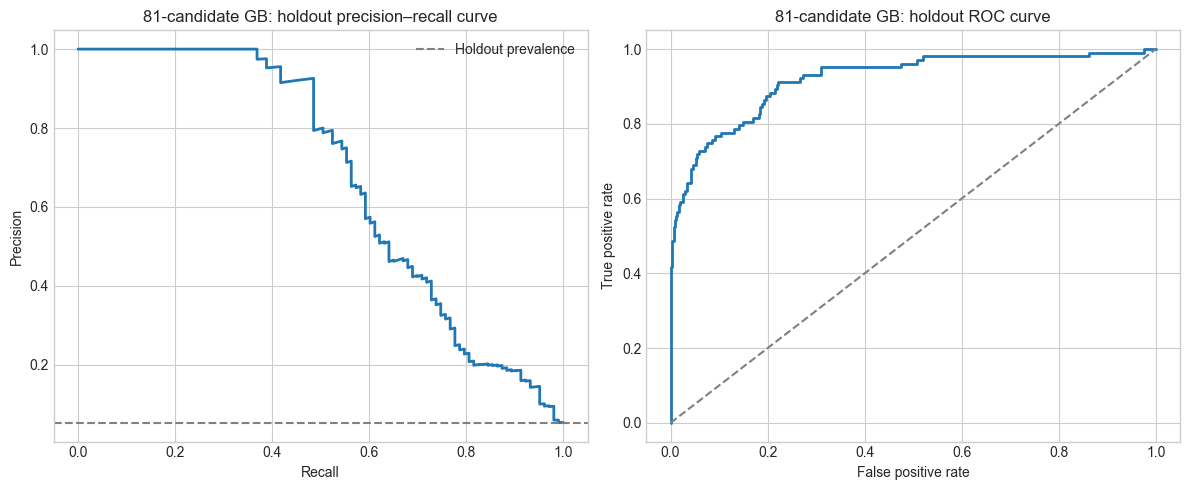

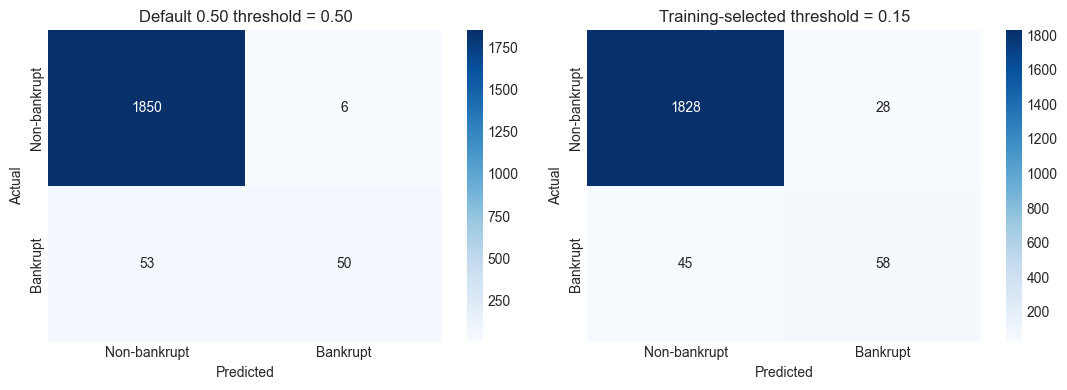


Section 13 complete. New tables: 21–24; new figures: 20–21.


In [20]:
# ============================================================================
# 13. Expanded 81-candidate Gradient Boosting search + final holdout evaluation
# ============================================================================

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_fscore_support

# --- 13A. All-feature preprocessing, as supported by Section 11 ---
# Missingness indicators + median imputation + standard scaling;
# no SelectKBest (retain all financial ratios and generated indicators).
gb_refined_config = configurations['all_features']
gb_refined_base = make_experiment_pipeline('GradientBoosting', gb_refined_config)

# Re-estimate classifier hyperparameters; not just reusing the original
# 16-candidate best parameters.
gb_refined_param_grid = {
    'clf__n_estimators': [100, 200, 300],
    'clf__learning_rate': [0.03, 0.05, 0.1],
    'clf__max_depth': [2, 3, 5],
    'clf__min_samples_leaf': [10, 20, 40]
}
gb_refined_candidates = int(np.prod([len(v) for v in gb_refined_param_grid.values()]))
print(f'Expanded Gradient Boosting search: {gb_refined_candidates} candidates '
      f'x {experiment_cv.get_n_splits()} folds = '
      f'{gb_refined_candidates * experiment_cv.get_n_splits()} fits')

gb_refined_search = GridSearchCV(
    estimator=gb_refined_base,
    param_grid=gb_refined_param_grid,
    scoring='average_precision',
    cv=experiment_cv,
    n_jobs=N_JOBS,
    refit=True,
    return_train_score=True,
    verbose=1
)
gb_refined_search.fit(X_train, y_train)
gb_refined_best_pipe = gb_refined_search.best_estimator_

print('\nExpanded-search best CV average precision:',
      f'{gb_refined_search.best_score_:.4f}')
print('Expanded-search best hyperparameters:', gb_refined_search.best_params_)

# Save search results.
gb_refined_search_results = pd.DataFrame(gb_refined_search.cv_results_)
gb_refined_search_results.to_csv(
    os.path.join(TAB_DIR, '21_gb_81_candidate_search.csv'), index=False
)

# --- 13B. Training-only out-of-fold threshold selection ---
# cross_val_predict fits the selected parameter combination separately in
# each fold; it does not re-run hyperparameter search in each fold.
gb_refined_oof_proba = cross_val_predict(
    clone(gb_refined_best_pipe), X_train, y_train,
    cv=experiment_cv, method='predict_proba', n_jobs=N_JOBS
)[:, 1]

gb_refined_threshold_rows = []
for threshold in np.round(np.arange(0.10, 0.91, 0.05), 2):
    pred = (gb_refined_oof_proba >= threshold).astype(int)
    p, r, f, _ = precision_recall_fscore_support(
        y_train, pred, average='binary', zero_division=0
    )
    gb_refined_threshold_rows.append({
        'threshold': float(threshold), 'precision': p, 'recall': r,
        'f1': f, 'flagged_companies': int(pred.sum()),
        'bankruptcies_detected': int(((pred == 1) & (y_train == 1)).sum()),
        'bankruptcies_missed': int(((pred == 0) & (y_train == 1)).sum())
    })
gb_refined_threshold_table = pd.DataFrame(gb_refined_threshold_rows)
gb_refined_threshold = float(gb_refined_threshold_table.loc[
    gb_refined_threshold_table['f1'].idxmax(), 'threshold'
])
gb_refined_threshold_table.to_csv(
    os.path.join(TAB_DIR, '22_gb_81_candidate_training_thresholds.csv'), index=False
)
print(f'\nTraining OOF average precision: '
      f'{average_precision_score(y_train, gb_refined_oof_proba):.4f}')
print(f'Training-selected max-F1 threshold: {gb_refined_threshold:.2f}')
print(gb_refined_threshold_table.round(4).to_string(index=False))

# --- 13C. Evaluate the fitted expanded-search model on the holdout ---
# The best_estimator_ is refitted on the entire training partition by GridSearchCV.
gb_refined_holdout_proba = gb_refined_best_pipe.predict_proba(X_holdout)[:, 1]

gb_refined_holdout_rows = []
for label, threshold in [('Default 0.50', 0.50),
                         ('Training-selected', gb_refined_threshold)]:
    pred = (gb_refined_holdout_proba >= threshold).astype(int)
    gb_refined_holdout_rows.append({
        'model': 'GradientBoosting (81-candidate all-features)',
        'threshold_rule': label,
        'threshold': threshold,
        'PR-AUC': average_precision_score(y_holdout, gb_refined_holdout_proba),
        'ROC-AUC': roc_auc_score(y_holdout, gb_refined_holdout_proba),
        'Precision': precision_score(y_holdout, pred, zero_division=0),
        'Recall': recall_score(y_holdout, pred, zero_division=0),
        'F1': f1_score(y_holdout, pred, zero_division=0),
        'Accuracy': accuracy_score(y_holdout, pred),
        'TN': int(confusion_matrix(y_holdout, pred, labels=[0, 1])[0, 0]),
        'FP': int(confusion_matrix(y_holdout, pred, labels=[0, 1])[0, 1]),
        'FN': int(confusion_matrix(y_holdout, pred, labels=[0, 1])[1, 0]),
        'TP': int(confusion_matrix(y_holdout, pred, labels=[0, 1])[1, 1]),
    })
gb_refined_holdout_table = pd.DataFrame(gb_refined_holdout_rows)
gb_refined_holdout_table.to_csv(
    os.path.join(TAB_DIR, '23_gb_81_candidate_holdout_metrics.csv'), index=False
)
print('\nExpanded-search holdout performance:')
print(gb_refined_holdout_table.round(4).to_string(index=False))

# --- 13D. Compare against earlier original and all-feature results ---
gb_refined_comparison_rows = []

# The original section 9 holdout_df is preserved in memory only if it has not
# been reassigned; otherwise load the original saved result directly.
gb_refined_original_path = os.path.join(TAB_DIR, '13_holdout_performance.csv')
if os.path.exists(gb_refined_original_path):
    original_saved = pd.read_csv(gb_refined_original_path, index_col=0)
    if 'GradientBoosting' in original_saved.index:
        gb_refined_comparison_rows = [{
            'model': 'Original GB (30 features)',
            'PR-AUC': float(original_saved.loc['GradientBoosting', 'PR-AUC']),
            'ROC-AUC': float(original_saved.loc['GradientBoosting', 'ROC-AUC'])
        }]

gb_refined_prior_path = os.path.join(TAB_DIR, '19_refined_gb_holdout_metrics.csv')
if os.path.exists(gb_refined_prior_path):
    prior_saved = pd.read_csv(gb_refined_prior_path)
    if not prior_saved.empty:
        gb_refined_comparison_rows.append({
            'model': 'Prior all-feature GB (original hyperparameters)',
            'PR-AUC': float(prior_saved.iloc[0]['PR-AUC']),
            'ROC-AUC': float(prior_saved.iloc[0]['ROC-AUC'])
        })
gb_refined_comparison_rows.append({
    'model': 'Expanded 81-candidate all-feature GB',
    'PR-AUC': gb_refined_holdout_rows[0]['PR-AUC'],
    'ROC-AUC': gb_refined_holdout_rows[0]['ROC-AUC']
})
gb_refined_comparison = pd.DataFrame(gb_refined_comparison_rows)
gb_refined_comparison.to_csv(
    os.path.join(TAB_DIR, '24_gb_expanded_search_comparison.csv'), index=False
)
print('\nHoldout discrimination comparison:')
print(gb_refined_comparison.round(4).to_string(index=False))

# --- 13E. Holdout PR/ROC curves and confusion matrices ---
gb_refined_pr, gb_refined_rec, _ = precision_recall_curve(
    y_holdout, gb_refined_holdout_proba
)
gb_refined_fpr, gb_refined_tpr, _ = roc_curve(
    y_holdout, gb_refined_holdout_proba
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(gb_refined_rec, gb_refined_pr, lw=2)
axes[0].axhline(y_holdout.mean(), linestyle='--', color='gray',
                label='Holdout prevalence')
axes[0].set(xlabel='Recall', ylabel='Precision',
            title='81-candidate GB: holdout precision–recall curve')
axes[0].legend()
axes[1].plot(gb_refined_fpr, gb_refined_tpr, lw=2)
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate',
            title='81-candidate GB: holdout ROC curve')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '20_gb_81_candidate_holdout_curves.png'),
            dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, threshold) in zip(
    axes, [('Default 0.50', 0.50), ('Training-selected', gb_refined_threshold)]
):
    pred = (gb_refined_holdout_proba >= threshold).astype(int)
    cm = confusion_matrix(y_holdout, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-bankrupt', 'Bankrupt'],
                yticklabels=['Non-bankrupt', 'Bankrupt'])
    ax.set(xlabel='Predicted', ylabel='Actual',
           title=f'{label} threshold = {threshold:.2f}')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '21_gb_81_candidate_confusion_matrices.png'),
            dpi=150, bbox_inches='tight')
plt.show()

print('\nSection 13 complete. New tables: 21–24; new figures: 20–21.')
